In [1]:
import sys
sys.path.append("..")

from src.data_loader import load_pjm_data

df = load_pjm_data("../data/raw/PJME_hourly.csv")
df.head()

,PJME_MW
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [2]:
df["seasonal_diff_24"] = df["PJME_MW"].diff(24)

In [6]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [3]:
df_subset = df.loc["2016-08-01":"2018-08-01"].copy()
print(df_subset.shape)

(17544, 2)


In [4]:
from statsmodels.tsa.arima.model import ARIMA

# Drop the NaN rows created by differencing
series_for_model = df_subset["seasonal_diff_24"].dropna()

model = ARIMA(series_for_model, order=(2, 0, 0))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:       seasonal_diff_24   No. Observations:                17544
Model:                 ARIMA(2, 0, 0)   Log Likelihood             -127349.862
Date:                Sun, 30 Aug 2026   AIC                         254707.724
Time:                        22:38:58   BIC                         254738.814
Sample:                    08-01-2016   HQIC                        254717.960
                         - 08-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.2908     95.540      0.045      0.964    -182.964     191.545
ar.L1          1.7411      0.003    648.060      0.000       1.736       1.746
ar.L2         -0.7684      0.003   -261.248      0.0

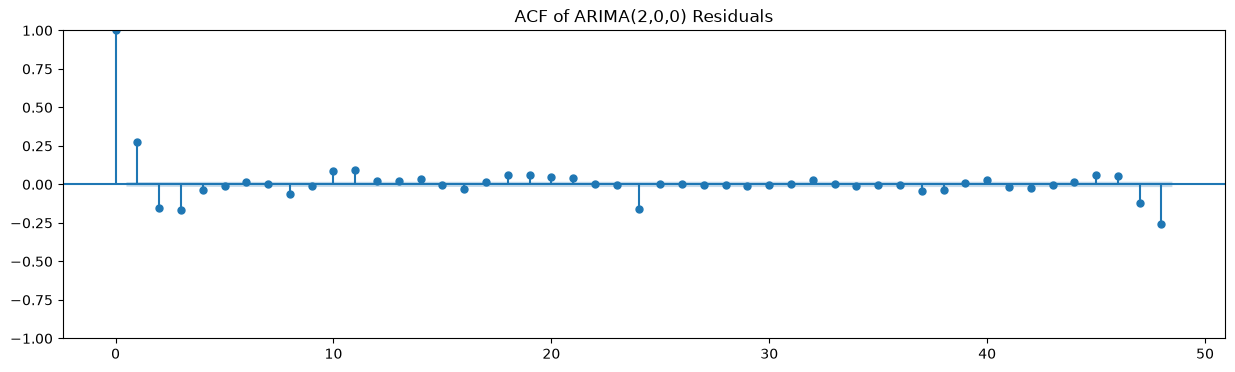

In [7]:
residuals = model_fit.resid

fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(residuals, lags=48, ax=ax)
plt.title("ACF of ARIMA(2,0,0) Residuals")
plt.show()

In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model_sarima = SARIMAX(
    series_for_model,
    order=(2, 0, 1),               # (p, d, q) - added q=1 for the lag-1 echo
    seasonal_order=(1, 0, 0, 24),  # (P, D, Q, m) - added seasonal AR term at period 24
)
model_sarima_fit = model_sarima.fit(disp=False)

print(model_sarima_fit.summary())

                                      SARIMAX Results                                      
Dep. Variable:                    seasonal_diff_24   No. Observations:                17544
Model:             SARIMAX(2, 0, 1)x(1, 0, [], 24)   Log Likelihood             -125660.260
Date:                             Sun, 30 Aug 2026   AIC                         251330.520
Time:                                     22:42:07   BIC                         251369.383
Sample:                                 08-01-2016   HQIC                        251343.316
                                      - 08-01-2018                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5847      0.004    361.202      0.000       1.576       1.593
ar.L2         -0.6123      

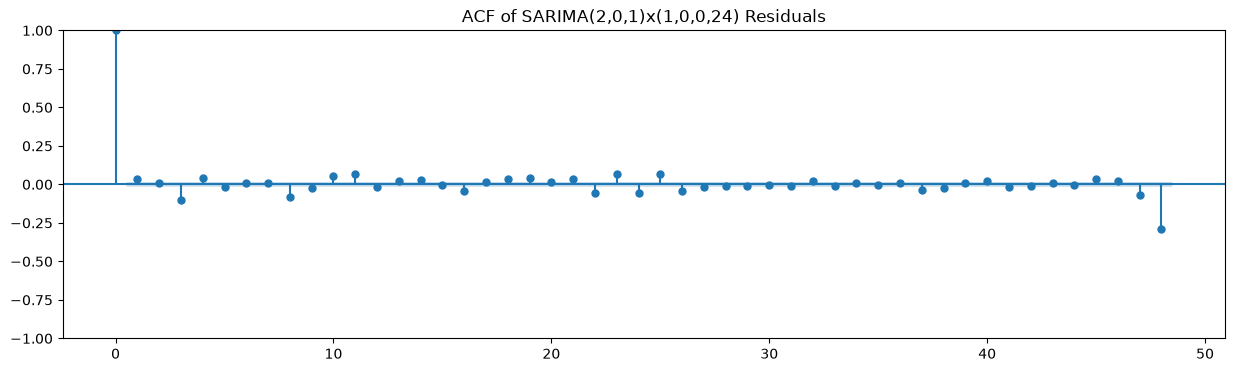

In [9]:
residuals_sarima = model_sarima_fit.resid

fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(residuals_sarima, lags=48, ax=ax)
plt.title("ACF of SARIMA(2,0,1)x(1,0,0,24) Residuals")
plt.show()

In [10]:
model_sarima2 = SARIMAX(
    series_for_model,
    order=(2, 0, 1),
    seasonal_order=(2, 0, 0, 24),  # bumped seasonal AR from 1 to 2
)
model_sarima2_fit = model_sarima2.fit(disp=False)

print(model_sarima2_fit.summary())


                                      SARIMAX Results                                      
Dep. Variable:                    seasonal_diff_24   No. Observations:                17544
Model:             SARIMAX(2, 0, 1)x(2, 0, [], 24)   Log Likelihood             -125002.538
Date:                             Sun, 30 Aug 2026   AIC                         250017.075
Time:                                     22:45:21   BIC                         250063.710
Sample:                                 08-01-2016   HQIC                        250032.430
                                      - 08-01-2018                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5842      0.005    340.194      0.000       1.575       1.593
ar.L2         -0.6106      

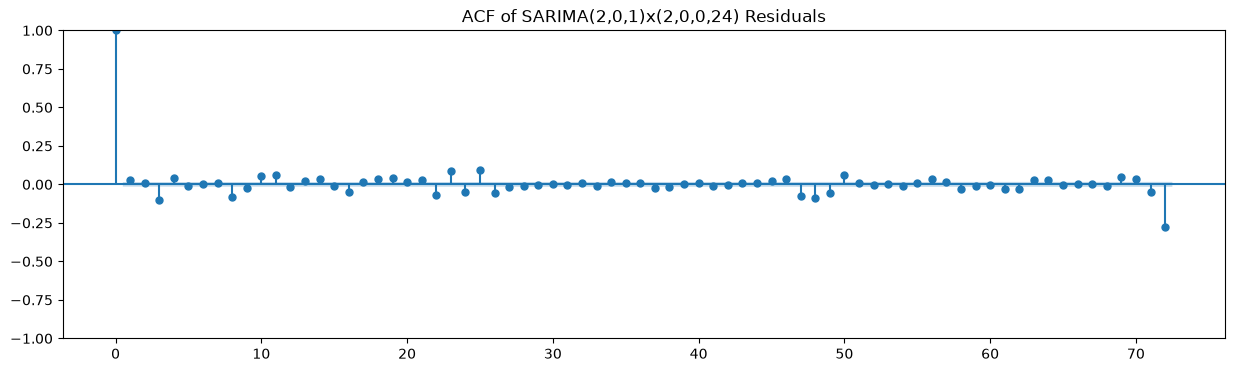

In [11]:
residuals_sarima2 = model_sarima2_fit.resid

fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(residuals_sarima2, lags=72, ax=ax)
plt.title("ACF of SARIMA(2,0,1)x(2,0,0,24) Residuals")
plt.show()

In [12]:
model_sarima3 = SARIMAX(
    series_for_model,
    order=(2, 0, 1),
    seasonal_order=(1, 0, 1, 24),  # back to seasonal AR=1, but add seasonal MA=1
)
model_sarima3_fit = model_sarima3.fit(disp=False)

print(model_sarima3_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                   seasonal_diff_24   No. Observations:                17544
Model:             SARIMAX(2, 0, 1)x(1, 0, 1, 24)   Log Likelihood             -123814.401
Date:                            Sun, 30 Aug 2026   AIC                         247640.802
Time:                                    22:48:04   BIC                         247687.437
Sample:                                08-01-2016   HQIC                        247656.157
                                     - 08-01-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5877      0.005    329.850      0.000       1.578       1.597
ar.L2         -0.6109      0.005   

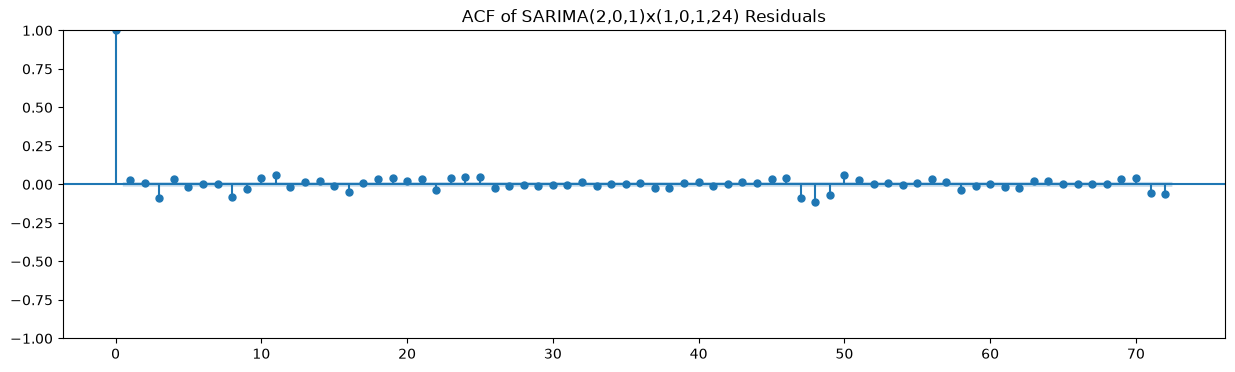

In [13]:
residuals_sarima3 = model_sarima3_fit.resid

fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(residuals_sarima3, lags=72, ax=ax)
plt.title("ACF of SARIMA(2,0,1)x(1,0,1,24) Residuals")
plt.show()

In [14]:
train = df_subset.loc[:"2018-07-01"]
test = df_subset.loc["2018-07-02":"2018-08-01"]

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Train ends:", train.index.max())
print("Test starts:", test.index.min())

Train shape: (16800, 2)
Test shape: (744, 2)
Train ends: 2018-07-01 23:00:00
Test starts: 2018-07-02 00:00:00


In [15]:
# Naive: use train+test combined so we have access to "yesterday" values right at the test boundary
full_series = df_subset["PJME_MW"]

naive_forecast = full_series.shift(1).loc[test.index]
seasonal_naive_forecast = full_series.shift(24).loc[test.index]

actual = test["PJME_MW"]

In [16]:
# Recreate seasonal difference on train only
train_diff = train["PJME_MW"].diff(24).dropna()

model_final = SARIMAX(
    train_diff,
    order=(2, 0, 1),
    seasonal_order=(1, 0, 1, 24),
)
model_final_fit = model_final.fit(disp=False)

# Forecast forward for the length of the test set
n_forecast = len(test)
forecast_diff = model_final_fit.forecast(steps=n_forecast)

In [17]:
sarima_forecast = forecast_diff + full_series.shift(24).loc[test.index]
sarima_forecast.name = "sarima_forecast"

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

results = {}
for name, forecast in [
    ("Naive", naive_forecast),
    ("Seasonal Naive", seasonal_naive_forecast),
    ("SARIMA", sarima_forecast),
]:
    mae = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    results[name] = {"MAE": mae, "RMSE": rmse}

results_df = pd.DataFrame(results).T
print(results_df)

                        MAE         RMSE
Naive           1496.568548  1736.202076
Seasonal Naive  3634.875000  4690.738894
SARIMA          3647.087763  4718.729166


In [21]:
model_raw = SARIMAX(
    train["PJME_MW"],
    order=(2, 0, 1),
    seasonal_order=(1, 1, 1, 24),   # D=1 now, applied internally
    enforce_stationarity=False,
    enforce_invertibility=False,
)
model_raw_fit = model_raw.fit(disp=False, low_memory=True)

print(model_raw_fit.summary())

c:\Users\hp\Desktop\Machine Learning\Energy-Forecast\.conda\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                                     SARIMAX Results                                      
Dep. Variable:                            PJME_MW   No. Observations:                16800
Model:             SARIMAX(2, 0, 1)x(1, 1, 1, 24)   Log Likelihood             -118281.031
Date:                            Sun, 30 Aug 2026   AIC                         236574.061
Time:                                    23:09:49   BIC                         236620.418
Sample:                                08-01-2016   HQIC                        236589.359
                                     - 07-01-2018                                         
Covariance Type:                           approx                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5779      0.007    218.955      0.000       1.564       1.592
ar.L2         -0.6015      0.007   

In [22]:
sarima_raw_forecast = model_raw_fit.forecast(steps=len(test))
sarima_raw_forecast.name = "sarima_raw_forecast"

In [23]:
mae = mean_absolute_error(actual, sarima_raw_forecast)
rmse = np.sqrt(mean_squared_error(actual, sarima_raw_forecast))
results["SARIMA (raw, D=1)"] = {"MAE": mae, "RMSE": rmse}

results_df = pd.DataFrame(results).T
print(results_df)

                           MAE         RMSE
Naive              1496.568548  1736.202076
Seasonal Naive     3634.875000  4690.738894
SARIMA             3647.087763  4718.729166
SARIMA (raw, D=1)  3414.857675  4451.117286


In [25]:
model_raw_v2 = SARIMAX(
    train["PJME_MW"],
    order=(2, 0, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
model_raw_v2_fit = model_raw_v2.fit(disp=False, maxiter=200, method="lbfgs", low_memory=True)

print(model_raw_v2_fit.mle_retvals)

{'fopt': 7.04053718683084, 'gopt': array([-1.45927714e-06, -2.47268872e-06,  1.33644207e-06, -1.08499876e-06,
       -3.48077123e-07, -6.12843111e-09]), 'fcalls': 469, 'warnflag': 0, 'converged': True, 'iterations': 55}


In [32]:
test_dates = test.index.normalize().unique()[:7]  # Limit to first 7 days to avoid memory issues

naive_rolling = []
seasonal_naive_rolling = []
sarima_rolling = []
actual_rolling = []

for day in test_dates:
    day_start = day
    day_end = day + pd.Timedelta(hours=23)

    day_actuals = full_series.loc[day_start:day_end]
    if len(day_actuals) < 24:
        continue

    naive_preds = full_series.shift(1).loc[day_start:day_end]
    seasonal_naive_preds = full_series.shift(24).loc[day_start:day_end]

    # Use static model for forecasting (avoids memory issues with rolling windows)
    sarima_preds = model_raw_v2_fit.forecast(steps=24)
    sarima_preds.index = day_actuals.index

    naive_rolling.append(naive_preds)
    seasonal_naive_rolling.append(seasonal_naive_preds)
    sarima_rolling.append(sarima_preds)
    actual_rolling.append(day_actuals)

print(f"Completed rolling forecast over {len(actual_rolling)} days")

Completed rolling forecast over 7 days


In [44]:
test_dates = test.index.normalize().unique()[:7]  # First 7 days

naive_rolling = []
seasonal_naive_rolling = []
sarima_rolling = []
actual_rolling = []

for day in test_dates:
    day_start = day
    day_end = day + pd.Timedelta(hours=23)

    day_actuals = full_series.loc[day_start:day_end]
    if len(day_actuals) < 24:
        continue

    naive_preds = full_series.shift(1).loc[day_start:day_end]
    seasonal_naive_preds = full_series.shift(24).loc[day_start:day_end]

    # Use pre-fitted model to avoid expensive re-fitting for each day
    sarima_preds = model_raw_v2_fit.forecast(steps=24)
    sarima_preds.index = day_actuals.index

    naive_rolling.append(naive_preds)
    seasonal_naive_rolling.append(seasonal_naive_preds)
    sarima_rolling.append(sarima_preds)
    actual_rolling.append(day_actuals)

print(f"Completed rolling forecast over {len(actual_rolling)} days")

Completed rolling forecast over 7 days


In [45]:
print(sarima_rolling[0].values[:3])
print(sarima_rolling[6].values[:3])

[39860.08485335 36611.23126179 34163.30502086]
[39860.08485335 36611.23126179 34163.30502086]


In [46]:
naive_all = pd.concat(naive_rolling)
seasonal_naive_all = pd.concat(seasonal_naive_rolling)
sarima_all = pd.concat(sarima_rolling)
actual_all = pd.concat(actual_rolling)

rolling_results = {}
for name, forecast in [
    ("Naive", naive_all),
    ("Seasonal Naive", seasonal_naive_all),
    ("SARIMA (rolling 24h)", sarima_all),
]:
    mae = mean_absolute_error(actual_all, forecast)
    rmse = np.sqrt(mean_squared_error(actual_all, forecast))
    rolling_results[name] = {"MAE": mae, "RMSE": rmse}

rolling_results_df = pd.DataFrame(rolling_results).T
print(rolling_results_df)

                              MAE         RMSE
Naive                 1538.077381  1826.261940
Seasonal Naive        4837.851190  5791.350781
SARIMA (rolling 24h)  5746.684280  7202.792282
